# LAB 12 — Artificial Neural Networks: The Perceptron
## Student Information
- **Name:** Saba Mahar
- **Roll No:** 023-24-0141
- **Section:** H
- **Date:** 11 November 2026

**Dataset:** Iris (sklearn built-in) · Use `random_state=42` everywhere · Write a 1–2 sentence interpretation under every plot and table.

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_iris, make_classification
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

np.random.seed(42)
iris = load_iris()
print("Iris loaded:", iris.data.shape, "| Classes:", iris.target_names)

Iris loaded: (150, 4) | Classes: ['setosa' 'versicolor' 'virginica']


## Part 1 — The Neuron From Scratch

### Task 1.1 — Weighted sum, step function and predict
Write `weighted_sum`, `step_function`, `predict`. Verify slide 16 (`predict([0.6,0.8],[2,3],-2)` → 1) and slide 17 (w=[1,−0.5], b=0.5; inputs [1,1],[2,1],[0,3] → 1, 1, 0).

In [19]:
# Task 1.1

def weighted_sum(w, x, b):
    return np.dot(w, x) + b

def step_function(z):
    return 1 if z >= 0 else 0

def predict(w, x, b):
    return step_function(weighted_sum(w, x, b))

print("Slide 16:", predict([0.6, 0.8], [2, 3], -2))

for x in [[1, 1], [2, 1], [0, 3]]:
    print("Slide 17:", x, "->", predict([1, -0.5], x, 0.5))

Slide 16: 1
Slide 17: [1, 1] -> 1
Slide 17: [2, 1] -> 1
Slide 17: [0, 3] -> 0


### Task 1.2 — One full epoch on the AND gate, by hand
AND: (0,0,0), (0,1,0), (1,0,0), (1,1,1). Start w=[0.2, −0.1], b=0, η=0.1. Print z, ŷ, e and the new w, b for each row; then the mistake count and "Converged!" / "Keep training.".

In [20]:
# Task 1.2

data = [(0, 0, 0), (0, 1, 0), (1, 0, 0), (1, 1, 1)]
w = np.array([0.2, -0.1])
b = 0
eta = 0.1
mistakes = 0

for x1, x2, y in data:
    x = np.array([x1, x2])
    z = np.dot(w, x) + b
    y_hat = step_function(z)
    e = y - y_hat
    if e != 0:
        mistakes += 1
    w = w + eta * e * x
    b = b + eta * e
    print("x =", [x1, x2], "| z =", round(z, 2), "| y_hat =", y_hat, "| e =", e, "| w =", w.round(2), "| b =", round(b, 2))

print("Final w:", w.round(2), "| Final b:", round(b, 2))
print("Mistakes:", mistakes)

if mistakes == 0:
    print("Converged!")
else:
    print("Keep training.")

x = [0, 0] | z = 0.0 | y_hat = 1 | e = -1 | w = [ 0.2 -0.1] | b = -0.1
x = [0, 1] | z = -0.2 | y_hat = 0 | e = 0 | w = [ 0.2 -0.1] | b = -0.1
x = [1, 0] | z = 0.1 | y_hat = 1 | e = -1 | w = [ 0.1 -0.1] | b = -0.2
x = [1, 1] | z = -0.2 | y_hat = 0 | e = 1 | w = [0.2 0. ] | b = -0.1
Final w: [0.2 0. ] | Final b: -0.1
Mistakes: 3
Keep training.


## Part 2 — Train a Perceptron From Scratch

### Task 2.1 — Implement `train_perceptron`
`train_perceptron(X, y, eta=0.1, max_epochs=100)`: start from zeros, update on every mistake, record mistakes per epoch, stop after a zero-mistake epoch. Train on OR (y = [0,1,1,1]) and print w, b.

In [21]:
# Task 2.1

def train_perceptron(X, y, eta=0.1, max_epochs=100):
    X = np.array(X, dtype=float)
    w = np.zeros(X.shape[1])
    b = 0.0
    mistakes = []

    for epoch in range(max_epochs):
        count = 0
        for x, target in zip(X, y):
            y_hat = predict(w, x, b)
            e = target - y_hat
            if e != 0:
                w = w + eta * e * x
                b = b + eta * e
                count += 1
        mistakes.append(count)
        if count == 0:
            break

    return w, b, mistakes

X_or = [[0, 0], [0, 1], [1, 0], [1, 1]]
y_or = [0, 1, 1, 1]

w_or, b_or, mistakes_or = train_perceptron(X_or, y_or)

print("Final w:", w_or.round(2))
print("Final b:", round(b_or, 2))
print("Mistakes per epoch:", mistakes_or)

Final w: [0.1 0.1]
Final b: -0.1
Mistakes per epoch: [2, 2, 1, 0]


### Task 2.2 — Plot mistakes per epoch
Title "Perceptron training on OR gate", axes "Epoch" / "Mistakes"; mark the final epoch with a red dot.

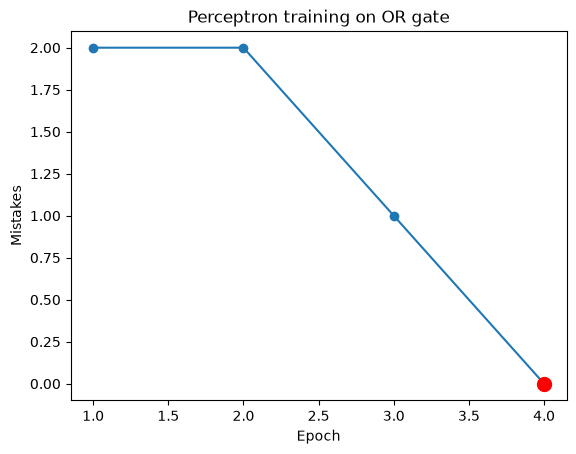

In [22]:
# Task 2.2

epochs = range(1, len(mistakes_or) + 1)

plt.plot(epochs, mistakes_or, marker="o")
plt.plot(len(mistakes_or), mistakes_or[-1], "ro", markersize=10)
plt.title("Perceptron training on OR gate")
plt.xlabel("Epoch")
plt.ylabel("Mistakes")
plt.show()

**Interpretation:** The mistakes went 2, 2, 1, 0, so the perceptron learned OR and stopped at epoch 4 as red dot.

## Part 3 — The Decision Boundary

### Task 3.1 — Plot the OR gate with its boundary
Boundary: x₂ = −(w₁/w₂)x₁ − b/w₂ over `np.linspace(-0.5, 1.5, 100)`. Class 0 blue circles, class 1 red squares, boundary black dashed. Write a reusable `plot_boundary(ax, w, b)` that handles w₂ = 0.

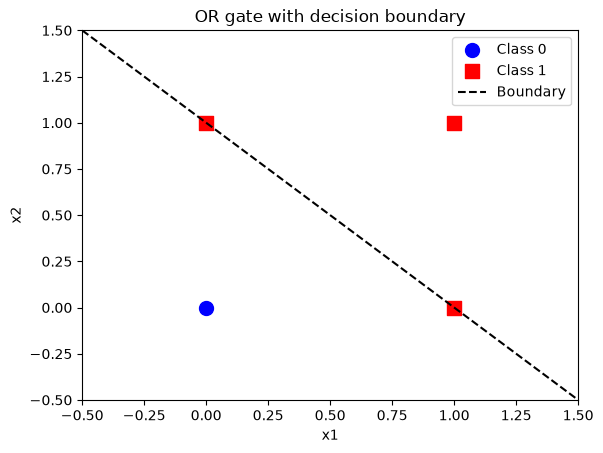

In [23]:
# Task 3.1

def plot_boundary(ax, w, b, xmin=-0.5, xmax=1.5):
    x1 = np.linspace(xmin, xmax, 100)
    if w[1] != 0:
        x2 = -(w[0] / w[1]) * x1 - b / w[1]
        ax.plot(x1, x2, "k--", label="Boundary")
    elif w[0] != 0:
        ax.axvline(-b / w[0], color="k", linestyle="--", label="Boundary")

X_or_arr = np.array(X_or)
y_or_arr = np.array(y_or)

fig, ax = plt.subplots()
ax.scatter(X_or_arr[y_or_arr == 0, 0], X_or_arr[y_or_arr == 0, 1], c="blue", marker="o", s=100, label="Class 0")
ax.scatter(X_or_arr[y_or_arr == 1, 0], X_or_arr[y_or_arr == 1, 1], c="red", marker="s", s=100, label="Class 1")
plot_boundary(ax, w_or, b_or)
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(-0.5, 1.5)
ax.set_title("OR gate with decision boundary")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.legend()
plt.show()

**Interpretation:** The line x₂ = −x₁ + 1 (w = [0.1, 0.1], b = −0.1) separates the two classes. The upper-right side is ŷ = 1; the points (0,1) and (1,0) sit exactly on the line and still count as 1 because z ≥ 0.

### Task 3.2 — With and without bias
Train both versions on X=[[1,0],[0,1],[2,1],[1,2]], y=[0,0,1,1]; plot the two boundaries side by side. Did the no-bias version converge?

With bias:    w = [0.1 0.1] | b = -0.2 | epochs = 4 | last mistakes = 0
Without bias: w = [0.1 0. ] | b = 0.0 | epochs = 100 | last mistakes = 2


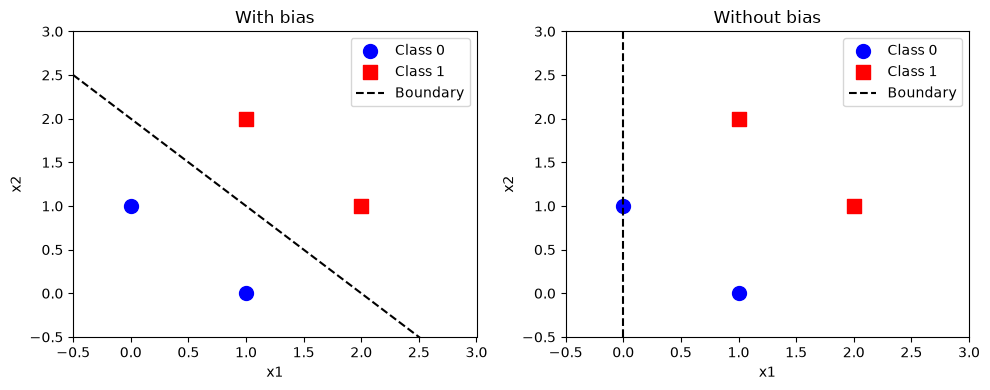

In [24]:
# Task 3.2

def train_perceptron_nobias(X, y, eta=0.1, max_epochs=100):
    X = np.array(X, dtype=float)
    w = np.zeros(X.shape[1])
    b = 0.0
    mistakes = []

    for epoch in range(max_epochs):
        count = 0
        for x, target in zip(X, y):
            y_hat = predict(w, x, b)
            e = target - y_hat
            if e != 0:
                w = w + eta * e * x
                count += 1
        mistakes.append(count)
        if count == 0:
            break

    return w, b, mistakes

X_t = np.array([[1, 0], [0, 1], [2, 1], [1, 2]])
y_t = np.array([0, 0, 1, 1])

w_bias, b_bias, m_bias = train_perceptron(X_t, y_t)
w_nob, b_nob, m_nob = train_perceptron_nobias(X_t, y_t)

print("With bias:    w =", w_bias.round(2), "| b =", round(b_bias, 2), "| epochs =", len(m_bias), "| last mistakes =", m_bias[-1])
print("Without bias: w =", w_nob.round(2), "| b =", b_nob, "| epochs =", len(m_nob), "| last mistakes =", m_nob[-1])

plt.figure(figsize=(10, 4))
for k, (w_k, b_k, title) in enumerate([(w_bias, b_bias, "With bias"), (w_nob, b_nob, "Without bias")], start=1):
    ax = plt.subplot(1, 2, k)
    ax.scatter(X_t[y_t == 0, 0], X_t[y_t == 0, 1], c="blue", marker="o", s=100, label="Class 0")
    ax.scatter(X_t[y_t == 1, 0], X_t[y_t == 1, 1], c="red", marker="s", s=100, label="Class 1")
    plot_boundary(ax, w_k, b_k, xmin=-0.5, xmax=3)
    ax.set_xlim(-0.5, 3)
    ax.set_ylim(-0.5, 3)
    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** With bias it converged in 4 epochs. Without bias it did not converge: it still had 2 mistakes after 100 epochs. Without a bias the line must pass through the origin, and no line through the origin can separate these points.

## Part 4 — The XOR Limitation

### Task 4.1 — Watch the perceptron fail
XOR: y = [0,1,1,0], `max_epochs=100`. Print final mistakes, w, b; plot mistakes per epoch and the boundary.

Final mistakes: 4
Final w: [-0.1  0. ]
Final b: 0.0


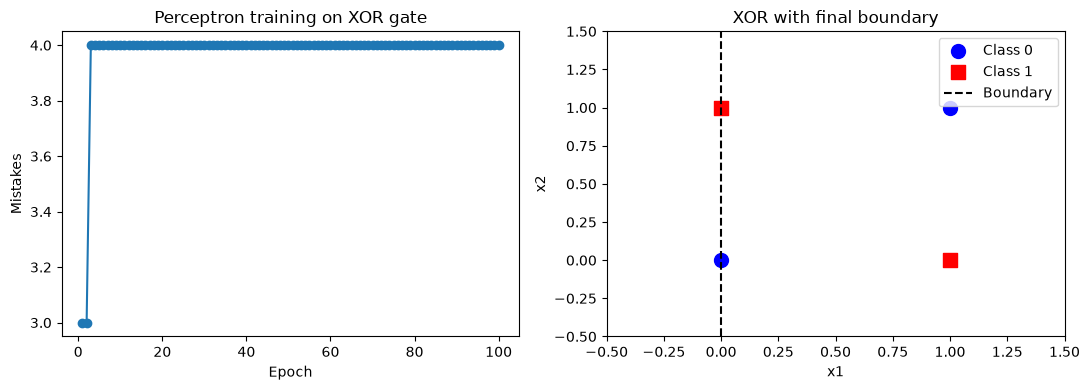

In [25]:
# Task 4.1

X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])

w_xor, b_xor, m_xor = train_perceptron(X_xor, y_xor, max_epochs=100)

print("Final mistakes:", m_xor[-1])
print("Final w:", w_xor.round(2))
print("Final b:", round(b_xor, 2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(range(1, len(m_xor) + 1), m_xor, marker="o")
ax[0].set_title("Perceptron training on XOR gate")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Mistakes")

ax[1].scatter(X_xor[y_xor == 0, 0], X_xor[y_xor == 0, 1], c="blue", marker="o", s=100, label="Class 0")
ax[1].scatter(X_xor[y_xor == 1, 0], X_xor[y_xor == 1, 1], c="red", marker="s", s=100, label="Class 1")
plot_boundary(ax[1], w_xor, b_xor)
ax[1].set_xlim(-0.5, 1.5)
ax[1].set_ylim(-0.5, 1.5)
ax[1].set_title("XOR with final boundary")
ax[1].set_xlabel("x1")
ax[1].set_ylabel("x2")
ax[1].legend()

plt.tight_layout()
plt.show()

**Interpretation:** It never reached zero mistakes; it stayed at 4 mistakes from epoch 3 to epoch 100. XOR is not linearly separable, so no single straight line can split the two classes.

### Task 4.2 — Confirm no weight vector works
`check_xor(w, b)` returns True only if all four XOR constraints hold. Test 10,000 random (w₁, w₂, b) in [−5, 5].

In [26]:
# Task 4.2

def check_xor(w, b):
    return (np.dot(w, [0, 0]) + b < 0) and (np.dot(w, [0, 1]) + b >= 0) and (np.dot(w, [1, 0]) + b >= 0) and (np.dot(w, [1, 1]) + b < 0)

W = np.random.uniform(-5, 5, (10000, 2))
B = np.random.uniform(-5, 5, 10000)

passed = 0
first = None

for w, b in zip(W, B):
    if check_xor(w, b):
        passed += 1
        if first is None:
            first = (w, b)

print("Triples tested: 10000")
print("Triples that pass:", passed)

if passed == 0:
    print("No solution found")
else:
    print("First passing triple:", first)

Triples tested: 10000
Triples that pass: 0
No solution found


## Part 5 — scikit-learn Perceptron on Iris

### Task 5.1 — Train and evaluate
Petal features (2, 3), Setosa vs rest; 70/30 stratified split; `Perceptron(random_state=42)`. Print accuracy, confusion matrix, report, `coef_`, `intercept_`.

In [27]:
# Task 5.1

X_iris = iris.data[:, (2, 3)]
y_iris = (iris.target == 0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X_iris, y_iris, test_size=0.30, random_state=42, stratify=y_iris
)

clf = Perceptron(random_state=42)
clf.fit(X_train, y_train)
pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, pred))
print("\nClassification report:")
print(classification_report(y_test, pred))
print("coef_:", clf.coef_)
print("intercept_:", clf.intercept_)

Accuracy: 1.0

Confusion matrix:
[[30  0]
 [ 0 15]]

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        30
           1       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

coef_: [[-1.3 -2.2]]
intercept_: [4.]


**Interpretation:** Accuracy is 1.0, so Setosa is easy to separate using petal length and width.

### Task 5.2 — Visualise the learned boundary
Boundary from `coef_[0]`, `intercept_[0]`; test set coloured by class; misclassified points as red ×.

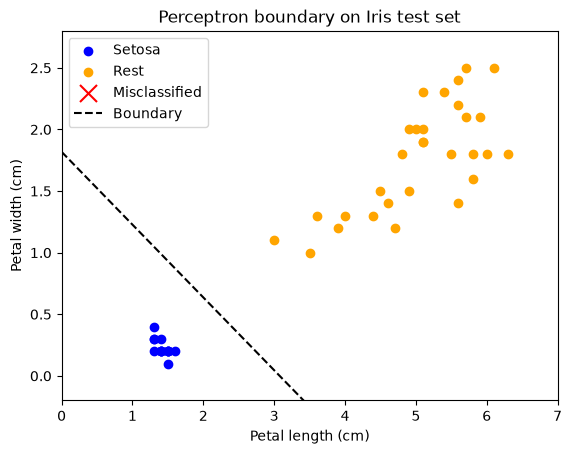

Misclassified test points: 0


In [28]:
# Task 5.2

fig, ax = plt.subplots()

ax.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], c="blue", label="Setosa")
ax.scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1], c="orange", label="Rest")

wrong = pred != y_test
ax.scatter(X_test[wrong, 0], X_test[wrong, 1], c="red", marker="x", s=150, label="Misclassified")

plot_boundary(ax, clf.coef_[0], clf.intercept_[0], xmin=0, xmax=7)
ax.set_xlim(0, 7)
ax.set_ylim(-0.2, 2.8)
ax.set_title("Perceptron boundary on Iris test set")
ax.set_xlabel("Petal length (cm)")
ax.set_ylabel("Petal width (cm)")
ax.legend()
plt.show()

print("Misclassified test points:", wrong.sum())

**Interpretation:** 0 test points are misclassified. The boundary is a straight line with Setosa (small petals) on one side and the other flowers on the other side.

### Task 5.3 — Effect of learning rate
`eta0` = 0.001, 0.1, 10.0. Table of eta0 | accuracy | `n_iter_` | `coef_`. Do the predictions change? What does η do when training starts from w = 0?

In [29]:
# Task 5.3

rows = []

for eta0 in [0.001, 0.1, 10.0]:
    model = Perceptron(eta0=eta0, random_state=42)
    model.fit(X_train, y_train)
    rows.append({
        "eta0": eta0,
        "accuracy": accuracy_score(y_test, model.predict(X_test)),
        "n_iter_": model.n_iter_,
        "coef_": model.coef_[0].round(4)
    })

pd.DataFrame(rows)

,eta0,accuracy,n_iter_,coef_
0,0.001,1.0,6,"[-0.0013, -0.0022]"
1,0.100,1.0,7,"[-0.13, -0.22]"
2,10.000,1.0,7,"[-13.0, -22.0]"


**Interpretation:** The predictions do not change (accuracy is 1.0 for all three). Starting from w = 0, η multiplies every update by the same amount, so the weights get bigger or smaller but the boundary stays in the same place.

## Part 6 — Multi-Class Classification

### Task 6.1 — All three Iris classes
All four features, `y = iris.target`, 70/30 stratified; `Perceptron(random_state=42, max_iter=1000)`. Print report, confusion matrix, `coef_.shape`. Which class is hardest?

In [30]:
# Task 6.1

X_all = iris.data
y_all = iris.target

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_all, y_all, test_size=0.30, random_state=42, stratify=y_all
)

clf_m = Perceptron(random_state=42, max_iter=1000)
clf_m.fit(X_train_m, y_train_m)
pred_m = clf_m.predict(X_test_m)

print("Classification report:")
print(classification_report(y_test_m, pred_m, target_names=iris.target_names, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_test_m, pred_m))
print("coef_.shape:", clf_m.coef_.shape)

Classification report:
              precision    recall  f1-score   support

      setosa       0.52      1.00      0.68        15
  versicolor       0.00      0.00      0.00        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.67        45
   macro avg       0.48      0.67      0.55        45
weighted avg       0.48      0.67      0.55        45

Confusion matrix:
[[15  0  0]
 [14  0  1]
 [ 0  0 15]]
coef_.shape: (3, 4)


**Interpretation:** Accuracy is only 0.67. Versicolor is the hardest class: its recall is 0, since 14 of the 15 Versicolor flowers were predicted as Setosa and 1 as Virginica. Versicolor sits between the other two classes, so one straight line cannot separate it from both.

### Task 6.2 — Perceptron vs Logistic Regression
`LogisticRegression(random_state=42, max_iter=200)` on the same split; side-by-side accuracy and macro-F1; why can it win (slide 32)?

In [31]:
# Task 6.2

lr = LogisticRegression(random_state=42, max_iter=200)
lr.fit(X_train_m, y_train_m)
pred_lr = lr.predict(X_test_m)

comparison = pd.DataFrame({
    "Model": ["Perceptron", "Logistic Regression"],
    "Accuracy": [accuracy_score(y_test_m, pred_m), accuracy_score(y_test_m, pred_lr)],
    "Macro-F1": [f1_score(y_test_m, pred_m, average="macro", zero_division=0), f1_score(y_test_m, pred_lr, average="macro", zero_division=0)]
})

comparison

,Model,Accuracy,Macro-F1
0,Perceptron,0.666667,0.549853
1,Logistic Regression,0.933333,0.933259


**Interpretation:** Logistic Regression is much better. The step function only says right or wrong, but the smooth sigmoid has a gradient that is never exactly zero, so it keeps improving the weights even when classes overlap.

## Part 7 — Graded Questions (5 marks)
Answer in the Markdown cells below, using your own numbers.

**Q1 [0.5 marks] — Manual update trace.** w = [0.5, −0.3], b = 0.2, η = 0.1, x = [1, 2], y = 0. Compute z and ŷ, then e, then the updated w₁, w₂ and b.

z = 0.5×1 + (−0.3)×2 + 0.2 = 0.1           
ŷ = 1 (z ≥ 0)                       
e = 0 − 1 = −1.

Update: w₁ = 0.5 + 0.1×(−1)×1 = **0.4**                            
w₂ = −0.3 + 0.1×(−1)×2 = **−0.5**                                 
b = 0.2 + 0.1×(−1) = **0.1**                                       

**Q2 [0.5 marks] — Boundary geometry.** After training on AND: w = [0.3, 0.2], b = −0.4. Write the boundary equation. Which side is (1, 1) on, and what is ŷ?

Boundary:                         
0.3x₁ + 0.2x₂ − 0.4 = 0                    
x₂ = −1.5x₁ + 2                            
For (1, 1): z = 0.3 + 0.2 − 0.4 = 0.1 ≥ 0                           
ŷ = 1 which is correct for AND.

**Q3 [1 mark] — XOR analysis.** (a) Show algebraically that the four XOR constraints cannot all hold. (b) Sketch XOR on x₁–x₂ axes (insert an image or a matplotlib plot) to show why no line separates it. (c) Name one architectural change that solves XOR.

**(a)** The four XOR conditions are:                                                
(0,0): b < 0                             
(0,1): w₂ + b ≥ 0                                                 
(1,0): w₁ + b ≥ 0                          
(1,1): w₁ + w₂ + b < 0                                  
Adding the 2nd and 3rd gives w₁ + w₂ ≥ −2b, and the 4th gives w₁ + w₂ < −b. So −2b < −b, which means b > 0, but the 1st condition says b < 0. This is a contradiction, so no weights work.


**(c)** Add a hidden layer.

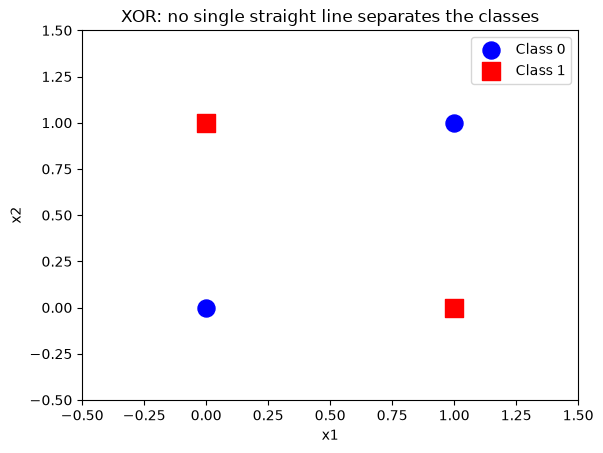

In [32]:
# Q3 (b)

plt.scatter([0, 1], [0, 1], c="blue", marker="o", s=150, label="Class 0")
plt.scatter([0, 1], [1, 0], c="red", marker="s", s=150, label="Class 1")
plt.title("XOR: no single straight line separates the classes")
plt.xlabel("x1")
plt.ylabel("x2")
plt.xlim(-0.5, 1.5)
plt.ylim(-0.5, 1.5)
plt.legend()
plt.show()

**Q4 [1.5 marks] — Iris extension.** Add sepal length (feature 0) so you use features (0, 2, 3). Retrain the Part 5 model; report accuracy and macro-F1. Does the extra feature help? Support your answer with numbers.

In [33]:
# Q4

X_q4 = iris.data[:, (0, 2, 3)]

Xtr4, Xte4, ytr4, yte4 = train_test_split(
    X_q4, y_iris, test_size=0.30, random_state=42, stratify=y_iris
)

clf4 = Perceptron(random_state=42)
clf4.fit(Xtr4, ytr4)
pred4 = clf4.predict(Xte4)

q4_table = pd.DataFrame({
    "Features": ["(2, 3)", "(0, 2, 3)"],
    "Accuracy": [accuracy_score(y_test, pred), accuracy_score(yte4, pred4)],
    "Macro-F1": [f1_score(y_test, pred, average="macro"), f1_score(yte4, pred4, average="macro")]
})

q4_table

,Features,Accuracy,Macro-F1
0,"(2, 3)",1.0,1.0
1,"(0, 2, 3)",1.0,1.0


**Q5 [1.5 marks] — Synthetic data.** `make_classification(n_samples=200, n_features=2, n_redundant=0, n_clusters_per_class=1, random_state=42)`, 70/30 split. Train your hand-built perceptron and sklearn's. Compare accuracy, epochs, final w and b; plot both boundaries side by side.

,Model,Accuracy,Epochs,w,b
0,Hand-built,0.816667,100,"[0.307, -0.256]",0.2
1,sklearn,0.666667,6,"[2.281, 0.58]",2.0


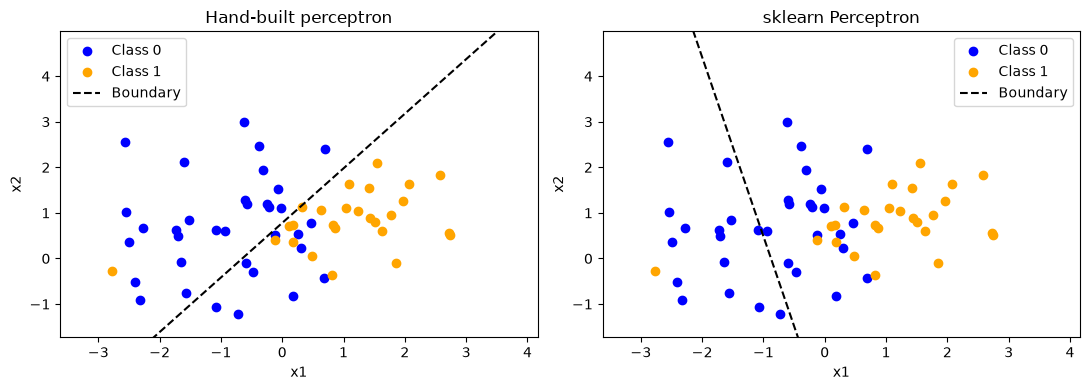

In [34]:
# Q5

Xs, ys = make_classification(n_samples=200, n_features=2, n_redundant=0, n_clusters_per_class=1, random_state=42)

Xs_train, Xs_test, ys_train, ys_test = train_test_split(Xs, ys, test_size=0.30, random_state=42)

w_hand, b_hand, m_hand = train_perceptron(Xs_train, ys_train)
pred_hand = np.array([predict(w_hand, x, b_hand) for x in Xs_test])

clf_s = Perceptron(random_state=42)
clf_s.fit(Xs_train, ys_train)
pred_sk = clf_s.predict(Xs_test)

q5_table = pd.DataFrame({
    "Model": ["Hand-built", "sklearn"],
    "Accuracy": [accuracy_score(ys_test, pred_hand), accuracy_score(ys_test, pred_sk)],
    "Epochs": [len(m_hand), clf_s.n_iter_],
    "w": [w_hand.round(3), clf_s.coef_[0].round(3)],
    "b": [round(b_hand, 3), round(clf_s.intercept_[0], 3)]
})
display(q5_table)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for a, w_k, b_k, title in [(ax[0], w_hand, b_hand, "Hand-built perceptron"), (ax[1], clf_s.coef_[0], clf_s.intercept_[0], "sklearn Perceptron")]:
    a.scatter(Xs_test[ys_test == 0, 0], Xs_test[ys_test == 0, 1], c="blue", label="Class 0")
    a.scatter(Xs_test[ys_test == 1, 0], Xs_test[ys_test == 1, 1], c="orange", label="Class 1")
    plot_boundary(a, w_k, b_k, xmin=Xs[:, 0].min() - 0.5, xmax=Xs[:, 0].max() + 0.5)
    a.set_xlim(Xs[:, 0].min() - 0.5, Xs[:, 0].max() + 0.5)
    a.set_ylim(Xs[:, 1].min() - 0.5, Xs[:, 1].max() + 0.5)
    a.set_title(title)
    a.set_xlabel("x1")
    a.set_ylabel("x2")
    a.legend()

plt.tight_layout()
plt.show()